# 14 · 亲手重训融合模型
## 目标
查看一行排序样本，训练 LightGBM，改变特征或负样本数量，再解释一条预测。
冠军使用 **binary classifier** 给候选打分，不是 LambdaRank；这里保留这个目标函数。
## 准备
[排序器代码](../reclab/competition/ranking.py) · [完整实验入口](../reclab/competition/experiment.py)。
以下训练格使用真实 t1 的全部官方候选与固定用户分区；只展示 select 成绩，方便你做实验。

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd()
if not (ROOT / "reclab").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code
from reclab.competition import data
from reclab.competition.teaching import load_run, style, bar_scores
style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
run, rows, features = load_run()
print("实际训练快照:", run.name)

实际训练快照: 20261030T115556803593-cloud-restore


## 步骤 1 · label 与特征必须分开
每个用户 1 个正例、99 个候选负例。候选是官方提前给定的，不是在知道答案后“补进召回池”。
特征矩阵中没有用户 ID、商品 ID、label 或分区。fit、select、audit 均按完整用户分组。

In [2]:
first_user = rows.query("market == 't1' and partition == 'fit'").userId.iloc[0]
mask = rows.market.eq("t1") & rows.userId.eq(first_user)
graph_columns = [c for c in features if c.startswith("graph_layers") and c != "graph_layers0"]
inspect_columns = ["target_user_rating_count", "target_item_rating_count", "icf_local", "icf_s1", "icf_all_iuf"] + graph_columns[:1]
sample = rows.loc[mask, ["userId", "itemId", "label", "partition"]].join(features.loc[mask, inspect_columns])
display(sample.sort_values("label", ascending=False).head(8))
print("样本正负比:", rows.loc[mask].label.value_counts().to_dict())

,userId,itemId,label,partition,target_user_rating_count,target_item_rating_count,icf_local,icf_s1,icf_all_iuf,graph_layers2
86,t1U1005570,P1026107,1,fit,5.0,10.0,0.000000,0.000000,0.000000,0.235096
0,t1U1005570,P1005811,0,fit,5.0,19.0,0.075901,0.046836,0.030729,0.229921
63,t1U1005570,P1024716,0,fit,5.0,7.0,0.000000,0.003632,0.007091,0.412555
72,t1U1005570,P1015969,0,fit,5.0,673.0,0.022080,0.014206,0.011226,0.992087
71,t1U1005570,P1012765,0,fit,5.0,81.0,0.032284,0.018921,0.014960,0.868360
70,t1U1005570,P1012762,0,fit,5.0,11.0,0.000000,0.000000,0.000000,0.203922
69,t1U1005570,P1028229,0,fit,5.0,245.0,0.027676,0.016709,0.007334,0.243087
68,t1U1005570,P1026274,0,fit,5.0,8.0,0.000000,0.003686,0.003105,0.263098


样本正负比: {0: 99, 1: 1}


## 步骤 2 · 重训一个真实模型
修改三个变量之一，再运行本格和下一格：`COLUMNS`、`NEGATIVE_KEEP`、`LEAVES`。
此处保留正例，只对 fit 的负例下采样；select/audit 的 100 候选保持原样。
负采样后的概率不再能直接当原分布概率，更不能当线上 CTR。

In [3]:
import importlib
import reclab.competition.ranking as ranking_module
import reclab.competition.teaching as teaching_module
importlib.reload(ranking_module)
importlib.reload(teaching_module)
COLUMNS = list(features.columns)
NEGATIVE_KEEP = 99
LEAVES = 15
model, selection, experiment_path = teaching_module.sandbox_ranker(
    columns=COLUMNS, negative_keep=NEGATIVE_KEEP, leaves=LEAVES, tag="manual-baseline")
display(selection)
print("本次配置/模型保存:", experiment_path)

,market,users,ndcg10,hr10
0,t1,538,0.696011,0.789963
1,combined,538,0.696011,0.789963


本次配置/模型保存: /Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/artifacts/xmrec/experiments/20261030T115947230728


## 步骤 3 · 只改一个变量：99 个负例 → 9 个
这格会再训练一次，标签、用户划分、特征和叶子数不变。
留下不涨分的结果；不要因为某次消融不符合预期就删掉记录。

In [4]:
sampled_model, sampled_selection, sampled_path = teaching_module.sandbox_ranker(
    columns=COLUMNS, negative_keep=9, leaves=LEAVES, tag="negative-sampling-9")
comparison = pd.concat([selection.assign(experiment="99 negatives"), sampled_selection.assign(experiment="9 negatives")])
display(comparison[comparison.market.eq("t1")][["experiment", "users", "ndcg10", "hr10"]])

,experiment,users,ndcg10,hr10
0,99 negatives,538,0.696011,0.789963
0,9 negatives,538,0.691342,0.776952


## 步骤 4 · 树在用什么信息
gain 是训练过程的分裂增益，不能解释成因果贡献。下面再看同一条预测的 TreeSHAP log-odds 分解。
正负贡献加上偏置等于模型 raw score，不等于概率。

,feature,gain
14,icf_local,76522.053376
17,icf_all_iuf,15161.155351
18,icf_all_rating,8366.501459
16,icf_s3,6512.573406
8,target_user_rating_count,2074.465636
6,t1_train_item_count,1647.045635
20,graph_layers2,1561.719227
7,t1_train_5core_item_count,1298.185287
19,graph_layers0,1192.538080
9,target_user_rating_mean,1163.521230


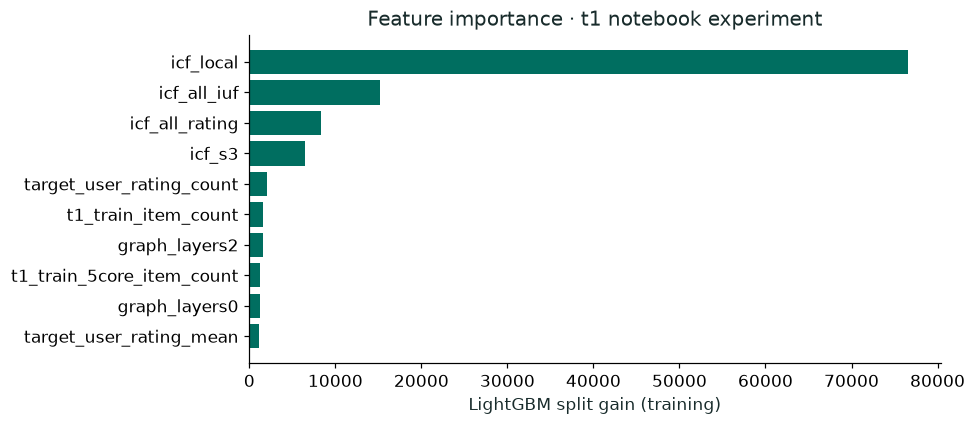

In [5]:
importance = pd.DataFrame({"feature": COLUMNS, "gain": model.booster_.feature_importance(importance_type="gain")}).sort_values("gain", ascending=False)
display(importance.head(10))
fig, ax = plt.subplots(figsize=(9,4))
top = importance.head(10).sort_values("gain")
ax.barh(top.feature, top.gain, color="#006e60")
ax.set(xlabel="LightGBM split gain (training)", title="Feature importance · t1 notebook experiment")
fig.tight_layout(); plt.show()

In [6]:
candidate = rows.query("market == 't1' and partition == 'select'").index[0]
x = features.loc[[candidate], COLUMNS]
contributions = model.booster_.predict(x, pred_contrib=True, num_threads=1)[0]
raw = model.booster_.predict(x, raw_score=True, num_threads=1)[0]
assert np.isclose(contributions.sum(), raw)
display(pd.DataFrame({"feature": COLUMNS + ["bias"], "log_odds_contribution": contributions}).sort_values("log_odds_contribution", key=abs, ascending=False).head(12))
print("raw score:", round(float(raw), 5), "probability:", round(float(model.predict_proba(x)[0,1]), 5))

,feature,log_odds_contribution
21,bias,-6.084144
17,icf_all_iuf,-0.333658
6,t1_train_item_count,-0.266225
13,t2_train_5core_item_count,-0.109099
14,icf_local,-0.079736
8,target_user_rating_count,0.076829
16,icf_s3,-0.075973
15,icf_s1,-0.072254
9,target_user_rating_mean,-0.070087
12,t2_train_item_count,-0.060302


raw score: -7.00451 probability: 0.00091


## 检查与下一步
如果把 `icf_s1` 从 COLUMNS 删除，t1 的 select 成绩一定会下降吗？先预测，再重跑步骤 2。
<details><summary>答案路径</summary>不一定。它可能冗余、有噪声，或者帮助的只是另一个市场。固定用户划分和训练配置做对照；单次小差异不能直接宣称稳定收益。</details>
进入 15 查看主实验已经冻结的选择与 audit 对照。